# Vogel oder Park

2014 zeichnet xkcd: Ob ein Foto in einem Nationalpark entstand, ist eine Abfrage auf den Koordinaten. Ob ein Vogel darauf ist, braucht „ein Forschungsteam und fünf Jahre“.

Dieses Notebook baut eine leichtere Variante davon, mit zwei festen Klassen: Vogel oder Park. In fünf Schritten:

1. Bilder holen
2. Aufteilen in Training und Validierung
3. Vortrainiertes Modell laden
4. Trainieren
5. Prüfen und ausprobieren

### Aufgaben

**Für alle** (rund 10 Minuten)

1. Alle Zellen ausführen und ablesen, wie viele Bilder das Modell richtig einordnet *(Einstieg)*
2. Die schwierigen Fälle: Wo liegt das Modell falsch, wo ist es unsicher?
3. Ein eigenes Foto testen

**Bonus**

4. Parkfotos verwischen: Ab wann hält das Modell sie für Vögel?
5. Knobelaufgabe: Warum ausgerechnet Unschärfe?

Zeitbox 15 Minuten, zu zweit. Jede Aufgabe steht noch einmal an der Stelle, an der ihr sie macht.

> **Aufgabe 1** (Einstieg): In Colab *Laufzeit → Alle ausführen*. Die Warnung, dass das Notebook nicht von Google stammt, mit *Trotzdem ausführen* bestätigen. Das Training in Schritt 4 dauert in Colab knapp eine Minute. In der Zeit die zwölf Bilder in Schritt 1 ansehen: Woran würdet ihr selbst einen Vogel von einem Park unterscheiden? Danach in Schritt 5 ablesen: Wie viele der 40 Validierungsbilder sind richtig? Fehler stehen in Rot.

## 1. Bilder holen

Vögel kommen von iNaturalist, Parks und Landschaften von Wikimedia Commons, beide ohne API-Key und nur mit freien Lizenzen. Liegen die Bilder schon im Ordner, lädt die Zelle nichts mehr.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/01-vogel-oder-park")

In [1]:
from helfer import lade_parks, lade_voegel, zeige_bilder

DATEN = "daten"
lade_voegel(DATEN, anzahl=100)
lade_parks(DATEN, anzahl=100)

vogel: 100 Bilder liegen schon da, kein Download
park: 100 Bilder liegen schon da, kein Download


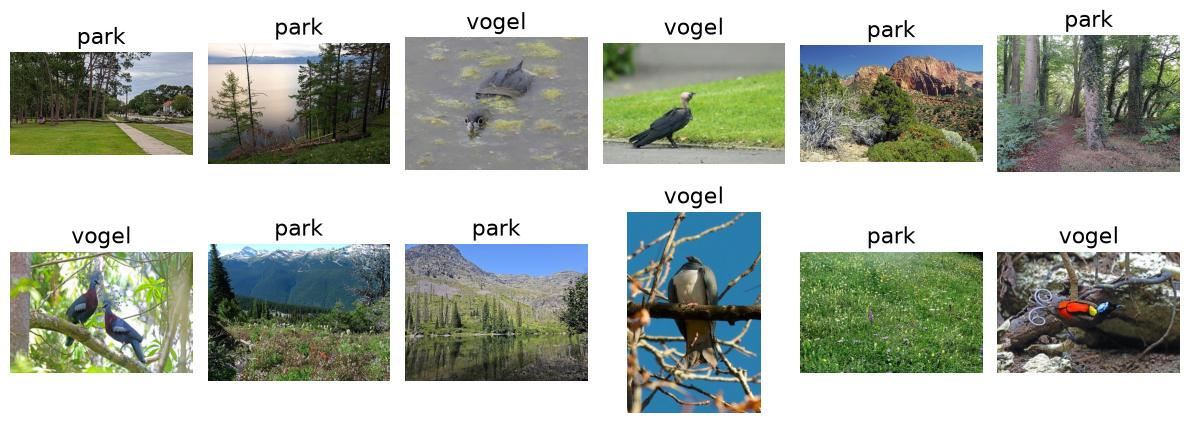

In [2]:
import random
from pathlib import Path

random.seed(7)
beispiele = random.sample(sorted(Path(DATEN).glob("*/*.jpg")), 12)
zeige_bilder(beispiele, [bild.parent.name for bild in beispiele])

## 2. Aufteilen in Training und Validierung

Das Modell lernt nur aus den Trainingsbildern. Die Validierungsbilder halten wir zurück: Sie zeigen später, ob es auch Bilder erkennt, die es nie gesehen hat.

In [3]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights

gewichte = ResNet18_Weights.DEFAULT
bilder = ImageFolder(DATEN, transform=gewichte.transforms())

idx_training, idx_validierung = train_test_split(
    range(len(bilder)), test_size=0.2, stratify=bilder.targets, random_state=42
)
training = DataLoader(Subset(bilder, idx_training), batch_size=16, shuffle=True)
validierung = DataLoader(Subset(bilder, idx_validierung), batch_size=32)

print(f"Klassen: {bilder.classes}")
print(f"{len(idx_training)} Bilder zum Trainieren, {len(idx_validierung)} zum Prüfen")

Klassen: ['park', 'vogel']
160 Bilder zum Trainieren, 40 zum Prüfen


## 3. Vortrainiertes Modell laden

ResNet-18 ist ein Bildklassifikator, trainiert auf ImageNet: 1,2 Millionen Fotos in 1'000 Kategorien. Seine Features, also Merkmale der Bilder, übernehmen wir unverändert und ersetzen nur die letzte Schicht. Die neue Schicht hat zwei Ausgänge, Park und Vogel, und zufällige Gewichte.

In [4]:
import torch
from torch import nn
from torchvision.models import resnet18

geraet = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

torch.manual_seed(42)
modell = resnet18(weights=gewichte)
for parameter in modell.parameters():
    parameter.requires_grad = False
modell.fc = nn.Linear(modell.fc.in_features, len(bilder.classes))
modell = modell.to(geraet).eval()  # auch die Statistiken der BatchNorm-Schichten bleiben fest

eingefroren = sum(p.numel() for p in modell.parameters() if not p.requires_grad)
lernbar = sum(p.numel() for p in modell.parameters() if p.requires_grad)
print(f"{eingefroren:_} Parameter übernommen, {lernbar:_} Parameter lernen wir".replace("_", "'"))

11'176'512 Parameter übernommen, 1'026 Parameter lernen wir


Vor dem Training sind die Gewichte der neuen Schicht zufällig. Das ist unsere Basislinie: Bei zwei gleich grossen Klassen trifft Raten im Schnitt 50 %.

In [5]:
def trefferquote():
    richtig = 0
    with torch.no_grad():
        for eingabe, label in validierung:
            richtig += (modell(eingabe.to(geraet)).argmax(1).cpu() == label).sum().item()
    return richtig / len(idx_validierung)


print(f"Vor dem Training: {trefferquote():.1%} richtig")

Vor dem Training: 37.5% richtig


## 4. Trainieren

Eine Schleife mit vier Schritten: Vorhersage berechnen, Fehler messen (Loss), Gradient bestimmen, Gewichte anpassen. Ein Durchgang durch alle Trainingsbilder heisst Epoche.

In [6]:
import time

fehlerfunktion = nn.CrossEntropyLoss()
optimierer = torch.optim.Adam(modell.fc.parameters(), lr=0.001)

start = time.perf_counter()
for epoche in range(1, 4):
    summe = 0.0
    for eingabe, label in training:
        eingabe, label = eingabe.to(geraet), label.to(geraet)

        vorhersage = modell(eingabe)              # Vorhersage
        loss = fehlerfunktion(vorhersage, label)  # Fehler messen
        optimierer.zero_grad()
        loss.backward()                           # Gradient
        optimierer.step()                         # Gewichte anpassen

        summe += loss.item() * len(label)

    print(f"Epoche {epoche}: Loss {summe / len(idx_training):.3f}, {trefferquote():.1%} richtig")

print(f"Dauer: {time.perf_counter() - start:.1f} Sekunden")

Epoche 1: Loss 0.566, 97.5% richtig


Epoche 2: Loss 0.212, 97.5% richtig


Epoche 3: Loss 0.108, 97.5% richtig
Dauer: 1.7 Sekunden


## 5. Prüfen und ausprobieren

Alle Validierungsbilder mit der Antwort des Modells, Fehler stehen in Rot. Die Zahl für Aufgabe 1 steht unter den Bildern.

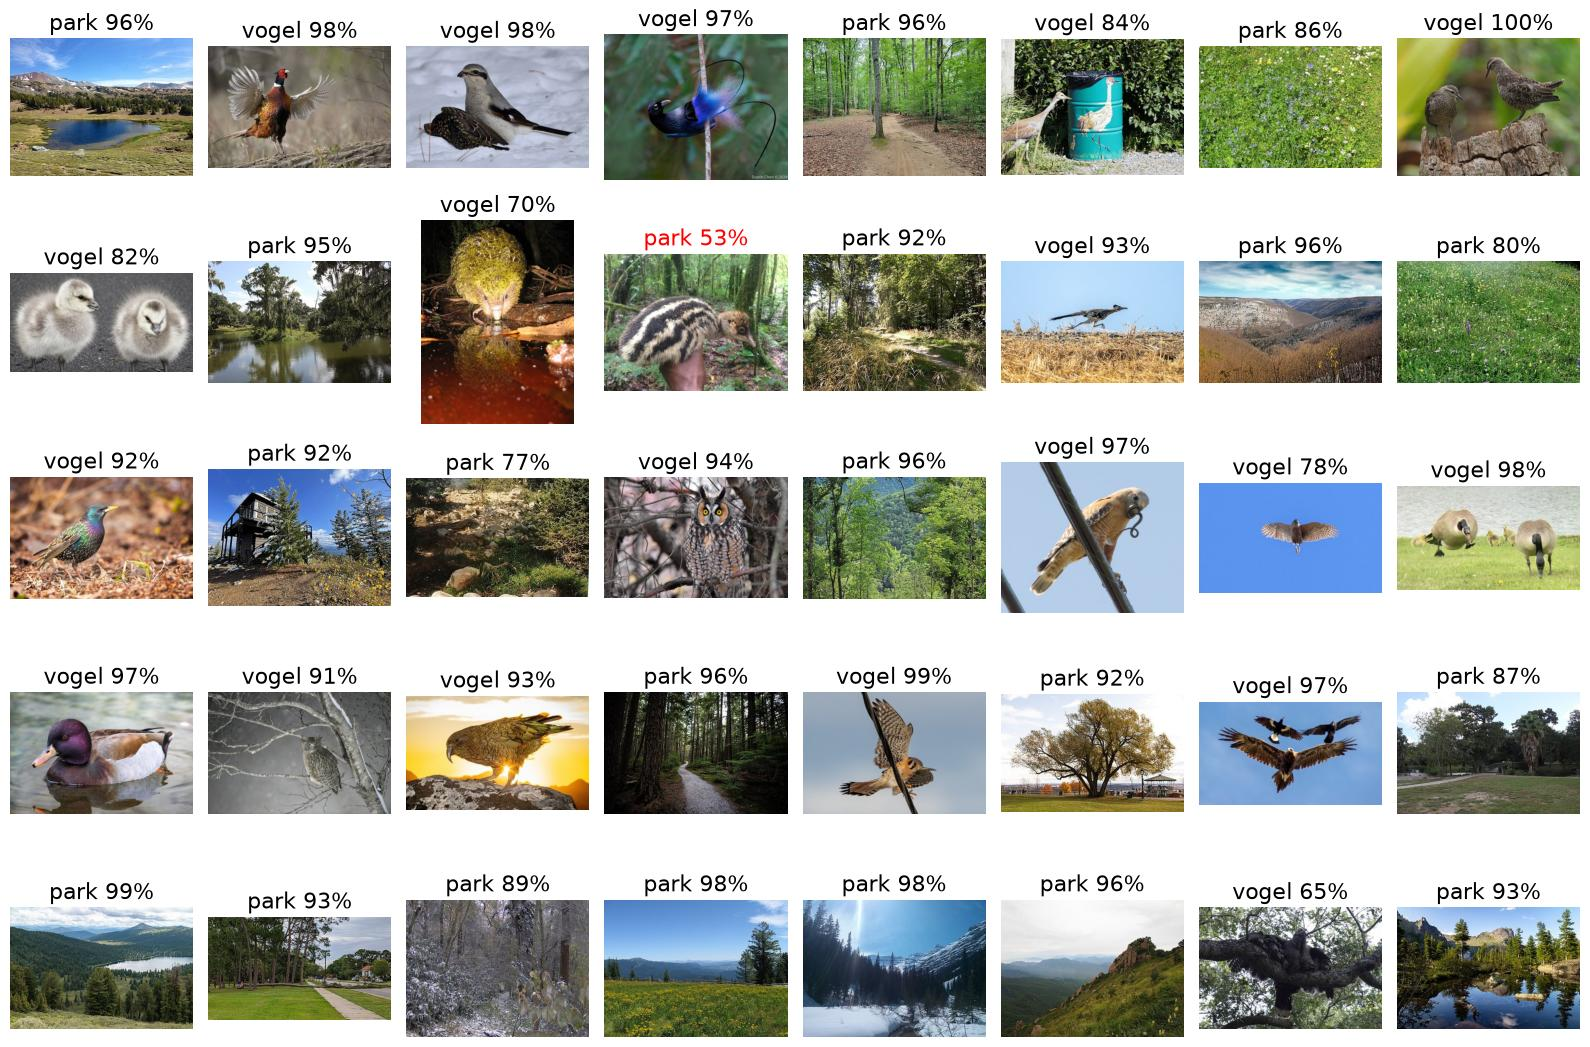

Validierung: 39 von 40 richtig


In [7]:
from PIL import Image


def wahrscheinlichkeiten(bild):
    """bild ist ein Dateipfad oder ein schon geöffnetes Bild."""
    if not isinstance(bild, Image.Image):
        bild = Image.open(bild)
    eingabe = gewichte.transforms()(bild.convert("RGB")).unsqueeze(0).to(geraet)
    with torch.no_grad():
        return torch.softmax(modell(eingabe), dim=1)[0].cpu()


def beschrifte(fotos):
    titel = []
    for foto in fotos:
        p = wahrscheinlichkeiten(foto)
        klasse = p.argmax().item()
        titel.append(f"{bilder.classes[klasse]} {p[klasse]:.0%}")
    return titel


pfade = [bilder.samples[i][0] for i in idx_validierung]
wahr = [bilder.classes[bilder.targets[i]] for i in idx_validierung]
titel = beschrifte(pfade)
farben = ["black" if t.split()[0] == w else "red" for t, w in zip(titel, wahr)]

zeige_bilder(pfade, titel, spalten=8, farben=farben)
print(f"Validierung: {farben.count('black')} von {len(pfade)} richtig")

Jetzt schwierige Fälle, die nicht aus dem Training stammen: ein Vogel neben einer Pizza, eine Zeichnung, Tiere im Park, ein Gemälde. Das Modell kennt nur zwei Antworten und muss eine davon geben. Über jedem Bild steht seine Antwort mit der Wahrscheinlichkeit.

> **Aufgabe 2**: Wo liegt das Modell falsch, wo ist es nur unsicher, etwa unter 70 %? Was ist an diesen Bildern anders als an den 160 Bildern, aus denen es gelernt hat?

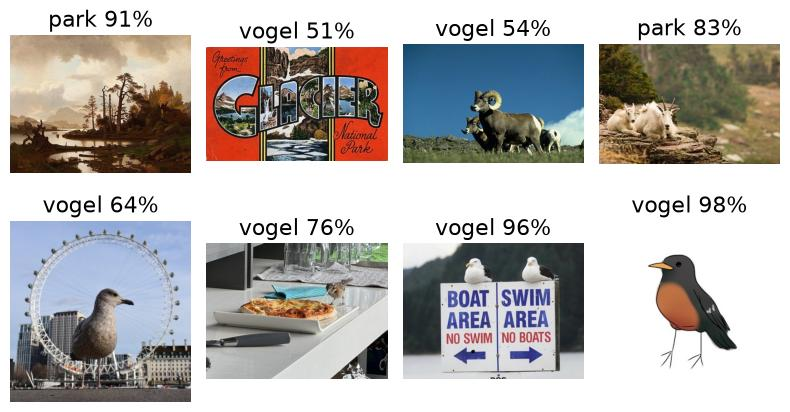

In [8]:
probe = sorted(Path("probe").glob("*.jpg"))
zeige_bilder(probe, beschrifte(probe), spalten=4)

<details><summary>Auflösung</summary>

Falsch liegt das Modell beim Widder: knapp über 50 % Vogel. Die Postkarte steht auf der Kippe, um 50 %; je nach Rechner landet sie knapp bei Park oder knapp bei Vogel. Unsicher ist es auch beim Vogel vor dem London Eye, um 60 %. Anders als im Training: Zeichnung, Gemälde und Postkarte sind keine Fotos, Widder und Ziegen sind Tiere, die keine Vögel sind, und beim London Eye ist der Vogel klein und das Bild voller Stadt. Für all das hat das Modell keine passende Antwort, es muss trotzdem Vogel oder Park sagen.

</details>

## Eigenes Foto

> **Aufgabe 3**: Testet ein eigenes Foto. Das Beispiel, eine Kohlmeise, steht schon da. Tragt in `FOTO` euer eigenes ein und führt die Zelle aus (*Shift + Enter*). Fertig, wenn unter der Zelle euer Foto mit der Antwort des Modells steht.

In `FOTO` steht eine von drei Möglichkeiten:

- ein Dateipfad: Das Beispiel ist eine Kohlmeise von Wikimedia Commons, gemeinfrei (CC0), die im Ordner `beispiel` liegt. Lokal ein eigenes Foto in den Ordner `probe` legen und den Dateinamen eintragen, etwa `"probe/vogel-london-eye.jpg"`.
- eine URL, die direkt auf ein Bild zeigt: im Browser Rechtsklick aufs Bild, *Bildadresse kopieren*. Manche Seiten, auch Wikimedia, lehnen Anfragen aus Colab ab (429); dann ein Bild von einer anderen Seite nehmen oder hochladen.
- `"hochladen"`: In Colab erscheint unter der Zelle ein Knopf für die Dateiauswahl.

Das Modell kennt nur Vogel und Park. Ein Foto von etwas anderem bekommt trotzdem eine der beiden Antworten.

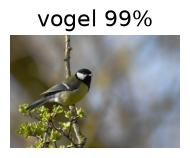

In [9]:
from helfer import hole_foto

FOTO = "beispiel/kohlmeise.jpg"

foto = hole_foto(FOTO)
if foto:
    zeige_bilder([foto], beschrifte([foto]), spalten=1)

## Bonus: Täuscht das Modell

> **Aufgabe 4** (Bonus): Die Zelle verwischt die 20 Parkfotos aus der Validierung und zeigt acht davon. Bei `RADIUS = 0` sind sie scharf, und das Modell sagt Park. Setzt `RADIUS` nacheinander auf 2, 4, 6 und 8 und führt die Zelle jedes Mal aus. Wie viele der 20 Parks hält das Modell jeweils für einen Vogel? Auf keinem ist einer zu sehen.

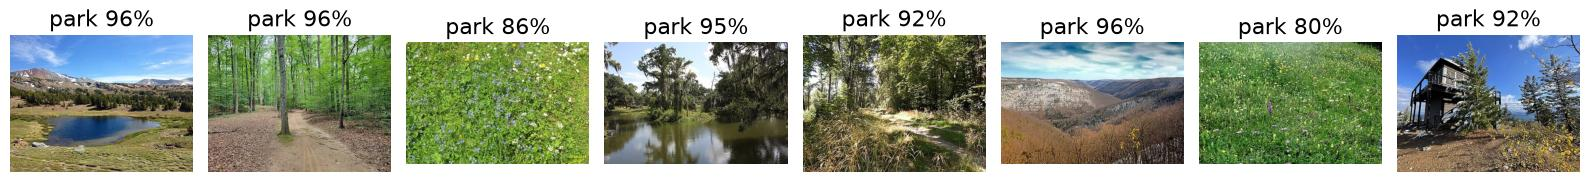

Radius 0: 0 von 20 Parks gelten als Vogel


In [10]:
from PIL import ImageFilter

RADIUS = 0  # Unschärfe in Pixeln, 0 ist scharf

parks = [pfad for pfad, w in zip(pfade, wahr) if w == "park"]  # die 20 Parks aus der Validierung
verwischt = [Image.open(pfad).convert("RGB").filter(ImageFilter.GaussianBlur(RADIUS)) for pfad in parks]
titel_verwischt = beschrifte(verwischt)

zeige_bilder(verwischt[:8], titel_verwischt[:8], spalten=8)
print(f"Radius {RADIUS}: {sum(t.startswith('vogel') for t in titel_verwischt)} von {len(parks)} Parks gelten als Vogel")

> **Aufgabe 5** (Bonus, Knobelaufgabe): Warum ausgerechnet Unschärfe? Findet die Ursache in den Bildern, aus denen das Modell gelernt hat. Und überlegt, warum die Validierung in Schritt 5 trotzdem fast alle 40 Bilder richtig meldet.

<details><summary>Tipp 1</summary>

Schaut die Vogelfotos in Schritt 1 und in Schritt 5 an: Was ist hinter dem Vogel zu sehen, und wie scharf ist es? Und wie scharf sind die Parks?

</details>
<details><summary>Tipp 2</summary>

Vögel und Parks kommen aus zwei verschiedenen Quellen (Schritt 1). Aus welchen Bildern hat Schritt 2 die Validierung genommen?

</details>

In [11]:
# @title Lösung (aufklappen)
# Vogelfotos entstehen meist mit dem Teleobjektiv: Der Vogel ist scharf, der Hintergrund verschwimmt.
# Parkfotos sind Landschaften, scharf bis in die Ferne. Das Modell hat deshalb nicht nur gelernt,
# wie ein Vogel aussieht, sondern auch: unscharfer Hintergrund heisst Vogel. Verwischt man einen Park,
# fehlt, was für Park spricht, und mit nur zwei Klassen bleibt Vogel übrig. Verwischte Vögel bleiben
# Vögel. Das heisst Shortcut Learning (Geirhos et al. 2020): Das Modell nimmt eine Abkürzung, die in
# diesen Daten zufällig stimmt.
#
# Die Validierung merkt davon nichts. Sie stammt aus denselben zwei Quellen, und dort gilt die
# Abkürzung genauso. Helfen würden Daten, in denen sie nicht gilt: Vögel und Parks aus derselben
# Quelle, Vögel in der Landschaft, Nahaufnahmen aus dem Park.


def als_vogel(liste, radius):
    """Wie viele Bilder der Liste gelten verwischt als Vogel?"""
    fotos = [Image.open(pfad).convert("RGB").filter(ImageFilter.GaussianBlur(radius)) for pfad in liste]
    return sum(t.startswith("vogel") for t in beschrifte(fotos))


parks_loesung = [pfad for pfad, w in zip(pfade, wahr) if w == "park"]
voegel_loesung = [pfad for pfad, w in zip(pfade, wahr) if w == "vogel"]
print("Radius  Parks als Vogel  Vögel als Vogel")
for radius_loesung in (0, 2, 4, 6, 8):
    voegel_text = f"{als_vogel(voegel_loesung, radius_loesung)} von 20" if radius_loesung in (0, 8) else ""
    print(f"{radius_loesung:>6}  {als_vogel(parks_loesung, radius_loesung):>2} von 20         {voegel_text}")

Radius  Parks als Vogel  Vögel als Vogel


     0   0 von 20         19 von 20
     2   0 von 20         


     4   3 von 20         
     6  10 von 20         


     8  18 von 20         19 von 20


## Was ihr gesehen habt

Ein Modell, das auf ImageNet 1'000 Kategorien gelernt hat, bekommt eine neue letzte Schicht mit 1'026 Parametern. Nach knapp einer Minute Training in Colab ordnet es fast alle Validierungsbilder richtig ein. Die fünf Jahre aus dem Comic stecken im vortrainierten Modell. Bei Bildern, die anders aussehen als die 160 Trainingsbilder, wird es unsicher oder liegt falsch, und es muss trotzdem immer eine der zwei Antworten geben.